# Code-Only System Prompt Comparison

This notebook compares the previous corrected baseline results with the new runs that add one system prompt:

> Output only the code, no explanations.

Comparison groups:

- **baseline_fixed**: `results/*_fixextractor.jsonl`
- **codeonly_system**: `results_codeonly/*_1_50.jsonl`

The comparison is paired by `(model, problem_id, template_id)`, so each code-only run is compared with the matching previous run.

In [1]:
from __future__ import annotations

import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
RESULTS_DIR = ROOT / "results"
CODEONLY_DIR = ROOT / "results_codeonly"
PROMPT_MATRIX_PATH = ROOT / "prompt_matrix_prompt_template.08.csv"
OUTPUT_DIR = ROOT / "analysis_outputs" / "codeonly_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("OUTPUT_DIR:", OUTPUT_DIR)

ROOT: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset
OUTPUT_DIR: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/codeonly_comparison


## 1. Load Results

The baseline and code-only files share the same `task_id` format: `problem_id_template_id`.

In [2]:
def read_jsonl(path: Path, condition: str) -> pd.DataFrame:
    rows = []
    with path.open("r", encoding="utf-8") as handle:
        for line_no, line in enumerate(handle, start=1):
            line = line.strip()
            if not line:
                continue
            row = json.loads(line)
            row["source_file"] = path.name
            row["condition"] = condition
            rows.append(row)
    return pd.DataFrame(rows)


def parse_task_id(value: object) -> tuple[int, int]:
    match = re.fullmatch(r"(\d+)_(\d+)", str(value))
    if not match:
        raise ValueError(f"Unexpected task_id: {value!r}")
    return int(match.group(1)), int(match.group(2))


def model_from_filename(path: Path) -> str:
    name = path.name
    name = name.removesuffix("_fixextractor.jsonl")
    name = name.removesuffix("_1_50.jsonl")
    name = name.removesuffix("_final.jsonl")
    return name

baseline_paths = sorted(RESULTS_DIR.glob("*_fixextractor.jsonl"))
codeonly_paths = sorted(CODEONLY_DIR.glob("*.jsonl"))

baseline = pd.concat([read_jsonl(path, "baseline_fixed") for path in baseline_paths], ignore_index=True)
codeonly = pd.concat([read_jsonl(path, "codeonly_system") for path in codeonly_paths], ignore_index=True)

for frame in [baseline, codeonly]:
    parsed = frame["task_id"].map(parse_task_id)
    frame["problem_id"] = parsed.map(lambda x: x[0])
    frame["template_id"] = parsed.map(lambda x: x[1])
    frame["model_short"] = frame["source_file"].map(lambda x: model_from_filename(Path(x)))

prompt_matrix = pd.read_csv(PROMPT_MATRIX_PATH).rename(columns={"ID": "template_id", "Role framing": "Role_framing"})

df = pd.concat([baseline, codeonly], ignore_index=True).merge(prompt_matrix, on="template_id", how="left", validate="many_to_one")

print("baseline files:", [p.name for p in baseline_paths])
print("code-only files:", [p.name for p in codeonly_paths])
print("rows:", len(df))
print(df.groupby(["condition", "model_short"]).size().to_string())
df.head(3)

baseline files: ['gemma2-9b_fixextractor.jsonl', 'llama3.1-8b_fixextractor.jsonl', 'qwen2.5-7b_fixextractor.jsonl']
code-only files: ['gemma2-9b_1_50.jsonl', 'llama3.1-8b_1_50.jsonl', 'qwen2.5-7b_1_50.jsonl']
rows: 5400
condition        model_short
baseline_fixed   gemma2-9b      900
                 llama3.1-8b    900
                 qwen2.5-7b     900
codeonly_system  gemma2-9b      900
                 llama3.1-8b    900
                 qwen2.5-7b     900


,timestamp,model,task_id,passed,tests_passed,tests_total,errors,duration_seconds,prompt_tokens,completion_tokens,response_text,extracted_code,fixextractor_timestamp,fixextractor_version,original_passed,original_tests_passed,original_errors,original_extracted_code_empty,source_file,condition,problem_id,template_id,model_short,Tone,Pressure,Role_framing,Format,ProblemID,Prompt,FinalPrompt
0,2026-04-23T10:20:17.804264,gemma2:9b,1_1,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",10.820442,205,214,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for f...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming grou...",2026-04-30T17:11:55.899697,v1_ast_plain_response_fallback,False,6.0,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,baseline_fixed,1,1,gemma2-9b,neutral,NaN,no role,plaintext,1,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Compl...,NaN
1,2026-04-23T10:20:25.565780,gemma2:9b,1_2,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.693842,232,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for f...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming grou...",2026-04-30T17:11:55.900614,v1_ast_plain_response_fallback,False,6.0,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,baseline_fixed,1,2,gemma2-9b,neutral,NaN,no role,json,1,"{\n ""instruction"": ""You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are ...",NaN
2,2026-04-23T10:20:33.334104,gemma2:9b,1_3,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.700639,275,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for f...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming grou...",2026-04-30T17:11:55.900845,v1_ast_plain_response_fallback,False,6.0,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,baseline_fixed,1,3,gemma2-9b,neutral,NaN,no role,xml,1,<prompt>\n<instruction>\nYou are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks ...,NaN


## 2. Derived Metrics

We compute the same performance and behavior metrics used in the previous analysis.

In [3]:
def safe_len(value: object) -> int:
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))


def error_text(errors: object) -> str:
    if isinstance(errors, list):
        return "\n".join(map(str, errors))
    if pd.isna(errors):
        return ""
    return str(errors)


def classify_error(errors: object, extracted_code: object) -> str:
    text = error_text(errors).lower()
    code = extracted_code if isinstance(extracted_code, str) else ""
    if "response is not valid python" in text:
        return "invalid_python_response"
    if not code.strip():
        return "missing_or_empty_code"
    if not text.strip():
        return "none"
    if "not defined" in text:
        return "name_not_defined"
    if "syntax" in text or "invalid syntax" in text:
        return "syntax_error"
    if "timeout" in text or "timed out" in text:
        return "timeout"
    if "importerror" in text or "no module named" in text:
        return "import_error"
    if "assert" in text or "test failed" in text:
        return "wrong_answer"
    return "other_runtime"


df["passed_int"] = df["passed"].astype(bool).astype(int)
df["tests_passed"] = pd.to_numeric(df["tests_passed"], errors="coerce")
df["tests_total"] = pd.to_numeric(df["tests_total"], errors="coerce")
df["tests_fraction"] = np.where(df["tests_total"] > 0, df["tests_passed"] / df["tests_total"], np.nan)
df["completion_tokens"] = pd.to_numeric(df["completion_tokens"], errors="coerce")
df["duration_seconds"] = pd.to_numeric(df["duration_seconds"], errors="coerce")
df["prompt_tokens"] = pd.to_numeric(df["prompt_tokens"], errors="coerce")
df["response_chars"] = df["response_text"].map(safe_len)
df["code_chars"] = df["extracted_code"].map(safe_len)
df["has_extracted_code"] = (df["code_chars"] > 0).astype(int)
df["extra_text_chars"] = (df["response_chars"] - df["code_chars"]).clip(lower=0)
df["extra_text_ratio"] = np.where(df["response_chars"] > 0, df["extra_text_chars"] / df["response_chars"], np.nan)
df["likely_code_only"] = ((df["has_extracted_code"] == 1) & (df["extra_text_ratio"] < 0.15)).astype(int)
df["error_text"] = df["errors"].map(error_text)
df["error_category"] = [classify_error(e, c) for e, c in zip(df["errors"], df["extracted_code"])]
df["invalid_python"] = df["error_category"].eq("invalid_python_response").astype(int)

df.to_csv(OUTPUT_DIR / "joined_codeonly_comparison.csv", index=False)
df[["condition", "model_short", "problem_id", "template_id", "Tone", "passed_int", "tests_fraction", "completion_tokens", "likely_code_only", "error_category"]].head()

,condition,model_short,problem_id,template_id,Tone,passed_int,tests_fraction,completion_tokens,likely_code_only,error_category
0,baseline_fixed,gemma2-9b,1,1,neutral,0,0.857143,214,1,wrong_answer
1,baseline_fixed,gemma2-9b,1,2,neutral,0,0.857143,220,1,wrong_answer
2,baseline_fixed,gemma2-9b,1,3,neutral,0,0.857143,220,1,wrong_answer
3,baseline_fixed,gemma2-9b,1,4,neutral,0,0.857143,212,1,wrong_answer
4,baseline_fixed,gemma2-9b,1,5,neutral,0,0.857143,222,1,wrong_answer


## 3. Overall Comparison

This table compares aggregate performance and behavior between the corrected baseline and the code-only system-prompt runs.

In [4]:
summary = (
    df.groupby("condition")
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        passes=("passed_int", "sum"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python", "mean"),
    )
    .reset_index()
)
summary.to_csv(OUTPUT_DIR / "overall_summary.csv", index=False)
summary.style.format({
    "pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_completion_tokens": "{:.0f}",
    "avg_duration_seconds": "{:.2f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}"
})

,condition,runs,pass_rate,passes,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate
0,baseline_fixed,2700,9.4%,254,13.3%,605,18.16,25.2%,0.2%
1,codeonly_system,2700,10.3%,277,15.7%,290,9.00,99.5%,0.6%


## 4. Model-Level Comparison

This shows whether the system prompt helps all models equally.

In [5]:
model_summary = (
    df.groupby(["model_short", "condition"])
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        passes=("passed_int", "sum"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python", "mean"),
    )
    .reset_index()
)
model_summary.to_csv(OUTPUT_DIR / "model_summary.csv", index=False)
model_summary.style.format({
    "pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_completion_tokens": "{:.0f}",
    "avg_duration_seconds": "{:.2f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}"
})

,model_short,condition,runs,pass_rate,passes,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate
0,gemma2-9b,baseline_fixed,900,9.4%,85,14.0%,601,19.56,25.9%,0.0%
1,gemma2-9b,codeonly_system,900,11.1%,100,18.9%,179,6.39,98.4%,0.2%
2,llama3.1-8b,baseline_fixed,900,5.3%,48,8.9%,562,16.33,23.0%,0.3%
3,llama3.1-8b,codeonly_system,900,6.2%,56,10.9%,389,11.57,100.0%,1.2%
4,qwen2.5-7b,baseline_fixed,900,13.4%,121,17.0%,653,18.59,26.7%,0.3%
5,qwen2.5-7b,codeonly_system,900,13.4%,121,17.3%,301,9.05,100.0%,0.2%


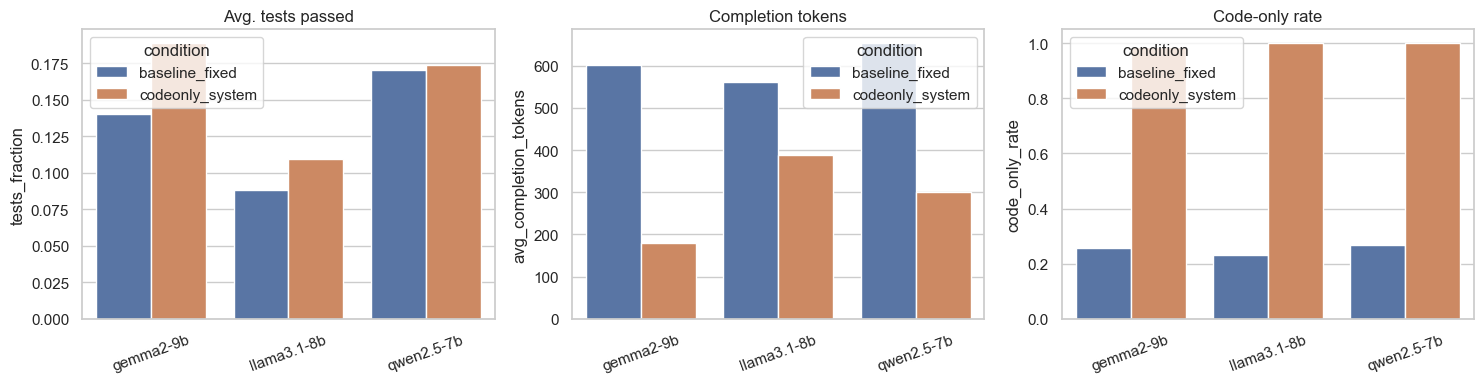

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["tests_fraction", "avg_completion_tokens", "code_only_rate"],
    ["Avg. tests passed", "Completion tokens", "Code-only rate"],
):
    sns.barplot(data=model_summary, x="model_short", y=metric, hue="condition", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Paired Deltas Versus Baseline

Because the two conditions use the same `(model, problem_id, template_id)` rows, we can compute direct paired differences:

```text
codeonly_system - baseline_fixed
```

Positive performance deltas mean the code-only system prompt improved the metric. Negative token/runtime deltas mean it made outputs shorter/faster.

In [7]:
metrics = ["passed_int", "tests_fraction", "completion_tokens", "duration_seconds", "likely_code_only", "extra_text_ratio", "invalid_python"]
keys = ["model_short", "problem_id", "template_id", "Tone", "Role_framing", "Format"]
wide = df.pivot_table(index=keys, columns="condition", values=metrics, aggfunc="first")
paired = wide.swaplevel(axis=1).sort_index(axis=1).reset_index()
for metric in metrics:
    paired[f"delta_{metric}"] = paired[("codeonly_system", metric)] - paired[("baseline_fixed", metric)]
paired.columns = ["_".join([str(x) for x in col if str(x) not in ["", "nan"]]).strip("_") if isinstance(col, tuple) else col for col in paired.columns]
paired.to_csv(OUTPUT_DIR / "paired_row_deltas.csv", index=False)

paired_summary = []
for metric in metrics:
    s = paired[f"delta_{metric}"].dropna()
    paired_summary.append({
        "metric": metric,
        "mean_delta": s.mean(),
        "median_delta": s.median(),
        "improved_count": int((s > 0).sum()),
        "worse_count": int((s < 0).sum()),
        "same_count": int((s == 0).sum()),
        "n": len(s),
    })
paired_summary = pd.DataFrame(paired_summary)
paired_summary.to_csv(OUTPUT_DIR / "paired_delta_summary.csv", index=False)
paired_summary.style.format({"mean_delta": "{:+.4f}", "median_delta": "{:+.4f}"})

,metric,mean_delta,median_delta,improved_count,worse_count,same_count,n
0,passed_int,+0.0085,+0.0000,158,135,2407,2700
1,tests_fraction,+0.0241,+0.0000,390,284,2026,2700
2,completion_tokens,-315.6237,-297.0000,142,2551,7,2700
3,duration_seconds,-9.1572,-8.2148,155,2545,0,2700
4,likely_code_only,+0.7430,+1.0000,2011,5,684,2700
5,extra_text_ratio,-0.3628,-0.3823,494,2152,54,2700
6,invalid_python,+0.0033,+0.0000,14,5,2681,2700


## 6. Paired Deltas by Model and Tone

This shows where the system prompt helped or hurt.

In [8]:
def summarize_deltas(group_cols):
    agg = {
        "delta_passed_int": ["mean", "sum"],
        "delta_tests_fraction": "mean",
        "delta_completion_tokens": "mean",
        "delta_duration_seconds": "mean",
        "delta_likely_code_only": "mean",
        "delta_extra_text_ratio": "mean",
        "delta_invalid_python": "mean",
    }
    out = paired.groupby(group_cols).agg(agg)
    out.columns = ["_".join(col).strip("_") for col in out.columns]
    return out.reset_index()

model_deltas = summarize_deltas(["model_short"])
tone_deltas = summarize_deltas(["Tone"])
model_tone_deltas = summarize_deltas(["model_short", "Tone"])

model_deltas.to_csv(OUTPUT_DIR / "model_deltas.csv", index=False)
tone_deltas.to_csv(OUTPUT_DIR / "tone_deltas.csv", index=False)
model_tone_deltas.to_csv(OUTPUT_DIR / "model_tone_deltas.csv", index=False)

print("Model deltas")
display(model_deltas.style.format({c: "{:+.4f}" for c in model_deltas.columns if c not in ["model_short"]}))
print("Tone deltas")
display(tone_deltas.style.format({c: "{:+.4f}" for c in tone_deltas.columns if c not in ["Tone"]}))
print("Model x tone deltas")
display(model_tone_deltas.style.format({c: "{:+.4f}" for c in model_tone_deltas.columns if c not in ["model_short", "Tone"]}))

Model deltas


,model_short,delta_passed_int_mean,delta_passed_int_sum,delta_tests_fraction_mean,delta_completion_tokens_mean,delta_duration_seconds_mean,delta_likely_code_only_mean,delta_extra_text_ratio_mean,delta_invalid_python_mean
0,gemma2-9b,+0.0167,+15.0000,+0.0483,-421.6689,-13.1693,+0.7256,-0.3667,+0.0022
1,llama3.1-8b,+0.0089,+8.0000,+0.0206,-172.8844,-4.7650,+0.7700,-0.3533,+0.0089
2,qwen2.5-7b,+0.0000,+0.0000,+0.0033,-352.3178,-9.5372,+0.7333,-0.3686,-0.0011


Tone deltas


,Tone,delta_passed_int_mean,delta_passed_int_sum,delta_tests_fraction_mean,delta_completion_tokens_mean,delta_duration_seconds_mean,delta_likely_code_only_mean,delta_extra_text_ratio_mean,delta_invalid_python_mean
0,aggressive,+0.0089,+8.0000,+0.0273,-405.9044,-11.6825,+0.9522,-0.5293,+0.0022
1,neutral,+0.0056,+5.0000,+0.0127,-152.2500,-4.4291,+0.2967,-0.1165,+0.0000
2,polite,+0.0111,+10.0000,+0.0322,-388.7167,-11.3599,+0.9800,-0.4428,+0.0078


Model x tone deltas


,model_short,Tone,delta_passed_int_mean,delta_passed_int_sum,delta_tests_fraction_mean,delta_completion_tokens_mean,delta_duration_seconds_mean,delta_likely_code_only_mean,delta_extra_text_ratio_mean,delta_invalid_python_mean
0,gemma2-9b,aggressive,+0.0167,+5.0000,+0.0467,-499.1600,-15.4985,+0.9933,-0.4922,+0.0000
1,gemma2-9b,neutral,+0.0167,+5.0000,+0.0276,-213.7567,-6.6860,+0.1967,-0.0907,+0.0033
2,gemma2-9b,polite,+0.0167,+5.0000,+0.0705,-552.0900,-17.3235,+0.9867,-0.5170,+0.0033
3,llama3.1-8b,aggressive,-0.0067,-2.0000,+0.0090,-208.9733,-5.7400,+0.8733,-0.5158,+0.0100
4,llama3.1-8b,neutral,+0.0167,+5.0000,+0.0243,-126.9067,-3.5120,+0.4833,-0.2085,-0.0033
5,llama3.1-8b,polite,+0.0167,+5.0000,+0.0286,-182.7733,-5.0431,+0.9533,-0.3357,+0.0200
6,qwen2.5-7b,aggressive,+0.0167,+5.0000,+0.0262,-509.5800,-13.8092,+0.9900,-0.5799,-0.0033
7,qwen2.5-7b,neutral,-0.0167,-5.0000,-0.0138,-116.0867,-3.0894,+0.2100,-0.0501,+0.0000
8,qwen2.5-7b,polite,+0.0000,+0.0000,-0.0024,-431.2867,-11.7131,+1.0000,-0.4757,+0.0000


## 7. Regression Check

This model estimates the average association of the code-only system prompt with performance/behavior while controlling for model, problem, and template.

```text
metric ~ condition + model fixed effects + problem fixed effects + template fixed effects
```

In [9]:
regression_rows = []
for metric in metrics:
    formula = f"{metric} ~ C(condition) + C(model_short) + C(problem_id) + C(template_id)"
    model_data = df[[metric, "condition", "model_short", "problem_id", "template_id"]].dropna()
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    term = "C(condition)[T.codeonly_system]"
    regression_rows.append({
        "metric": metric,
        "coef_codeonly_vs_baseline": result.params.get(term, np.nan),
        "std_err": result.bse.get(term, np.nan),
        "p_value": result.pvalues.get(term, np.nan),
        "nobs": result.nobs,
        "rsquared": result.rsquared,
    })
regression_summary = pd.DataFrame(regression_rows)
regression_summary.to_csv(OUTPUT_DIR / "condition_fixed_effect_regression.csv", index=False)
regression_summary.style.format({"coef_codeonly_vs_baseline": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}", "rsquared": "{:.4f}"})

,metric,coef_codeonly_vs_baseline,std_err,p_value,nobs,rsquared
0,passed_int,+0.0085,0.0071,0.2286,5400.000000,0.2573
1,tests_fraction,+0.0241,0.0076,0.0015,5400.000000,0.2824
2,completion_tokens,-315.6237,4.1297,0.0000,5400.000000,0.6528
3,duration_seconds,-9.1572,0.1215,0.0000,5400.000000,0.6376
4,likely_code_only,+0.7430,0.0073,0.0000,5400.000000,0.7008
5,extra_text_ratio,-0.3628,0.0048,0.0000,5400.000000,0.5824
6,invalid_python,+0.0033,0.0017,0.0495,5400.000000,0.0226


## 8. Error Category Comparison

This checks whether the system prompt changed failure modes.

In [10]:
error_summary = (
    df.groupby(["condition", "error_category"])
    .size()
    .rename("runs")
    .reset_index()
)
error_summary["rate"] = error_summary["runs"] / error_summary.groupby("condition")["runs"].transform("sum")
error_summary.to_csv(OUTPUT_DIR / "error_category_summary.csv", index=False)
error_summary.sort_values(["condition", "runs"], ascending=[True, False]).style.format({"rate": "{:.1%}"})

,condition,error_category,runs,rate
2,baseline_fixed,name_not_defined,1216,45.0%
6,baseline_fixed,wrong_answer,1185,43.9%
3,baseline_fixed,none,254,9.4%
5,baseline_fixed,timeout,26,1.0%
4,baseline_fixed,syntax_error,12,0.4%
1,baseline_fixed,invalid_python_response,6,0.2%
0,baseline_fixed,import_error,1,0.0%
9,codeonly_system,none,1476,54.7%
8,codeonly_system,name_not_defined,1021,37.8%
11,codeonly_system,wrong_answer,146,5.4%


## 8. Prompt-Factor Effects Within Each Condition

This section answers the key question:

> After forcing code-only output with a system prompt, do tone, role framing, and format still affect performance?

For each condition separately, we summarize performance/behavior by `Tone`, `Role_framing`, and `Format`. Then we run fixed-effect regressions within each condition:

```text
metric ~ Tone + Role_framing + Format + model fixed effects + problem fixed effects
```

This allows direct comparison of factor effects before and after adding the code-only system prompt.

In [11]:
factor_metrics = ["passed_int", "tests_fraction", "completion_tokens", "duration_seconds", "likely_code_only", "extra_text_ratio", "invalid_python"]
factors = ["Tone", "Role_framing", "Format"]

condition_factor_tables = []
for condition in ["baseline_fixed", "codeonly_system"]:
    sub = df[df["condition"].eq(condition)].copy()
    for factor in factors:
        table = (
            sub.groupby(factor, dropna=False)
            .agg(
                runs=("task_id", "size"),
                pass_rate=("passed_int", "mean"),
                tests_fraction=("tests_fraction", "mean"),
                avg_completion_tokens=("completion_tokens", "mean"),
                avg_duration_seconds=("duration_seconds", "mean"),
                code_only_rate=("likely_code_only", "mean"),
                invalid_python_rate=("invalid_python", "mean"),
            )
            .reset_index()
        )
        table.insert(0, "condition", condition)
        table.insert(1, "factor", factor)
        condition_factor_tables.append(table)

condition_factor_summary = pd.concat(condition_factor_tables, ignore_index=True)
condition_factor_summary.to_csv(OUTPUT_DIR / "condition_factor_summary.csv", index=False)

for condition in ["baseline_fixed", "codeonly_system"]:
    print(f"\n=== {condition} ===")
    for factor in factors:
        print(f"\n-- {factor} --")
        display(
            condition_factor_summary[
                condition_factor_summary["condition"].eq(condition)
                & condition_factor_summary["factor"].eq(factor)
            ].style.format({
                "pass_rate": "{:.1%}",
                "tests_fraction": "{:.1%}",
                "avg_completion_tokens": "{:.0f}",
                "avg_duration_seconds": "{:.2f}",
                "code_only_rate": "{:.1%}",
                "invalid_python_rate": "{:.1%}",
            })
        )


=== baseline_fixed ===

-- Tone --


,condition,factor,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,Role_framing,Format
0,baseline_fixed,Tone,aggressive,900,8.3%,11.7%,687,20.40,4.6%,0.4%,nan,nan
1,baseline_fixed,Tone,neutral,900,11.8%,16.9%,413,12.62,69.4%,0.2%,nan,nan
2,baseline_fixed,Tone,polite,900,8.1%,11.3%,716,21.47,1.6%,0.0%,nan,nan



-- Role_framing --


,condition,factor,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,Role_framing,Format
3,baseline_fixed,Role_framing,nan,1350,9.3%,13.6%,605,18.16,26.1%,0.1%,developer role,nan
4,baseline_fixed,Role_framing,nan,1350,9.5%,13.0%,605,18.16,24.2%,0.4%,no role,nan



-- Format --


,condition,factor,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,Role_framing,Format
5,baseline_fixed,Format,nan,900,8.8%,12.5%,612,18.31,21.1%,0.2%,nan,json
6,baseline_fixed,Format,nan,900,9.7%,13.9%,603,18.07,23.6%,0.1%,nan,plaintext
7,baseline_fixed,Format,nan,900,9.8%,13.5%,601,18.10,30.9%,0.3%,nan,xml


... (2 outputs left out)


-- Role_framing --


,condition,factor,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,Role_framing,Format
11,codeonly_system,Role_framing,nan,1350,10.1%,15.5%,292,9.08,99.6%,0.5%,developer role,nan
12,codeonly_system,Role_framing,nan,1350,10.4%,15.9%,287,8.93,99.4%,0.6%,no role,nan



-- Format --


,condition,factor,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,Role_framing,Format
13,codeonly_system,Format,nan,900,9.2%,14.6%,286,8.91,99.2%,1.0%,nan,json
14,codeonly_system,Format,nan,900,10.3%,15.4%,290,9.01,99.8%,0.3%,nan,plaintext
15,codeonly_system,Format,nan,900,11.2%,17.2%,292,9.10,99.4%,0.3%,nan,xml


In [12]:
def factor_regressions_for_condition(condition: str) -> pd.DataFrame:
    sub = df[df["condition"].eq(condition)].copy()
    rows = []
    for metric in factor_metrics:
        formula = f"{metric} ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)"
        model_data = sub[[metric, "Tone", "Role_framing", "Format", "model_short", "problem_id"]].dropna()
        result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
        for term, coef in result.params.items():
            if "Tone" in term or "Role_framing" in term or "Format" in term:
                rows.append({
                    "condition": condition,
                    "metric": metric,
                    "term": term,
                    "coef": coef,
                    "std_err": result.bse[term],
                    "p_value": result.pvalues[term],
                    "nobs": result.nobs,
                })
    return pd.DataFrame(rows)

factor_regression = pd.concat([
    factor_regressions_for_condition("baseline_fixed"),
    factor_regressions_for_condition("codeonly_system"),
], ignore_index=True)
factor_regression.to_csv(OUTPUT_DIR / "condition_factor_fixed_effect_regression.csv", index=False)

# Show correctness-related coefficients first.
correctness_terms = factor_regression[factor_regression["metric"].isin(["passed_int", "tests_fraction"])].copy()
display(correctness_terms.style.format({"coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"}))

,condition,metric,term,coef,std_err,p_value,nobs
0,baseline_fixed,passed_int,C(Tone)[T.neutral],+0.0344,0.0123,0.0050,2700.000000
1,baseline_fixed,passed_int,C(Tone)[T.polite],-0.0022,0.0119,0.8520,2700.000000
2,baseline_fixed,passed_int,C(Role_framing)[T.no role],+0.0015,0.0099,0.8815,2700.000000
3,baseline_fixed,passed_int,C(Format)[T.plaintext],+0.0089,0.0120,0.4573,2700.000000
4,baseline_fixed,passed_int,C(Format)[T.xml],+0.0100,0.0123,0.4153,2700.000000
5,baseline_fixed,tests_fraction,C(Tone)[T.neutral],+0.0525,0.0133,0.0001,2700.000000
6,baseline_fixed,tests_fraction,C(Tone)[T.polite],-0.0038,0.0129,0.7670,2700.000000
7,baseline_fixed,tests_fraction,C(Role_framing)[T.no role],-0.0065,0.0107,0.5481,2700.000000
8,baseline_fixed,tests_fraction,C(Format)[T.plaintext],+0.0140,0.0130,0.2828,2700.000000
9,baseline_fixed,tests_fraction,C(Format)[T.xml],+0.0100,0.0132,0.4475,2700.000000


In [13]:
# Compact side-by-side table for the most important factor coefficients.
important_terms = [
    "C(Tone)[T.neutral]",
    "C(Tone)[T.polite]",
    "C(Role_framing)[T.no role]",
    "C(Format)[T.plaintext]",
    "C(Format)[T.xml]",
]
compact = factor_regression[
    factor_regression["metric"].isin(["passed_int", "tests_fraction", "completion_tokens", "likely_code_only"])
    & factor_regression["term"].isin(important_terms)
].copy()
compact_pivot = compact.pivot_table(index=["metric", "term"], columns="condition", values=["coef", "p_value"], aggfunc="first")
compact.to_csv(OUTPUT_DIR / "condition_factor_key_terms.csv", index=False)
compact_pivot

coef                        p_value                
condition                                    baseline_fixed codeonly_system baseline_fixed codeonly_system
metric            term                                                                                    
completion_tokens C(Format)[T.plaintext]          -9.180000    3.812222e+00   2.174977e-01    3.275195e-01
                  C(Format)[T.xml]               -10.925556    6.287778e+00   1.390231e-01    1.452153e-01
                  C(Role_framing)[T.no role]      -0.422963   -5.719259e+00   9.445041e-01    1.002609e-01
                  C(Tone)[T.neutral]            -274.133333   -2.047889e+01  3.504915e-257    1.934135e-07
                  C(Tone)[T.polite]               29.517778    4.670556e+01   4.202912e-05    2.752109e-25
likely_code_only  C(Format)[T.plaintext]           0.024444    5.555556e-03   8.586793e-02    7.954386e-02
                  C(Format)[T.xml]                 0.097778    2.222222e-03   9.769945e-12    5.259726e-01
                  C(Role_framing)[T.no role]      -0.019259   -1.481481e-03   9.323490e-02    5.634738e-01
                  C(Tone)[T.neutral]               0.648889   -6.666667e-03   0.000000e+00    3.844355e-02
                  C(Tone)[T.polite]               -0.030000   -2.222222e-03   6.097487e-04    3.995549e-01
passed_int        C(Format)[T.plaintext]           0.008889    1.111111e-02   4.573214e-01    3.631460e-01
                  C(Format)[T.xml]                 0.010000    2.000000e-02   4.153395e-01    1.059631e-01
                  C(Role_framing)[T.no role]       0.001481    3.703704e-03   8.815108e-01    7.150755e-01
                  C(Tone)[T.neutral]               0.034444    3.111111e-02   4.967971e-03    1.314345e-02
                  C(Tone)[T.polite]               -0.002222   -2.424276e-16   8.519675e-01    1.000000e+00
tests_fraction    C(Format)[T.plaintext]           0.013968    7.777778e-03   2.827612e-01    5.475208e-01
                  C(Format)[T.xml]                 0.010000    2.603175e-02   4.475093e-01    4.672087e-02
                  C(Role_framing)[T.no role]      -0.006455    4.021164e-03   5.481058e-01    7.069098e-01
                  C(Tone)[T.neutral]               0.052540    3.793651e-02   7.422135e-05    4.115886e-03
                  C(Tone)[T.polite]               -0.003810    1.111111e-03   7.669855e-01    9.311390e-01

## Visual Summary: Overall Before vs Code-Only

These charts show the high-level tradeoff: code-only greatly improves compliance and speed, while performance improves more modestly.

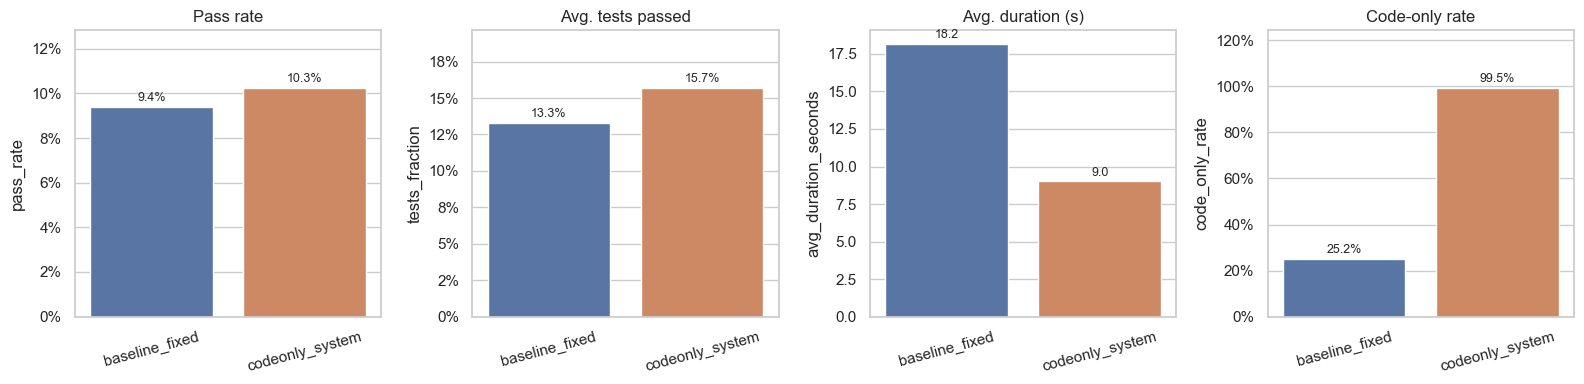

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
visual_metrics = [
    ("pass_rate", "Pass rate", "percent"),
    ("tests_fraction", "Avg. tests passed", "percent"),
    ("avg_duration_seconds", "Avg. duration (s)", "number"),
    ("code_only_rate", "Code-only rate", "percent"),
]
for ax, (metric, title, kind) in zip(axes, visual_metrics):
    sns.barplot(data=summary, x="condition", y=metric, ax=ax, hue="condition", legend=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    if kind == "percent":
        ax.set_ylim(0, max(summary[metric].max() * 1.25, 0.05))
        ax.yaxis.set_major_formatter(lambda x, pos: f"{100*x:.0f}%")
    for container in ax.containers:
        labels = [f"{100*v.get_height():.1f}%" if kind == "percent" else f"{v.get_height():.1f}" for v in container]
        ax.bar_label(container, labels=labels, fontsize=9, padding=2)
plt.tight_layout()
plt.show()

## Visual Summary: Model-Level Changes

These charts show that the code-only system prompt helps Gemma and Llama more than Qwen on exact pass rate, while all models become much more code-only and shorter.

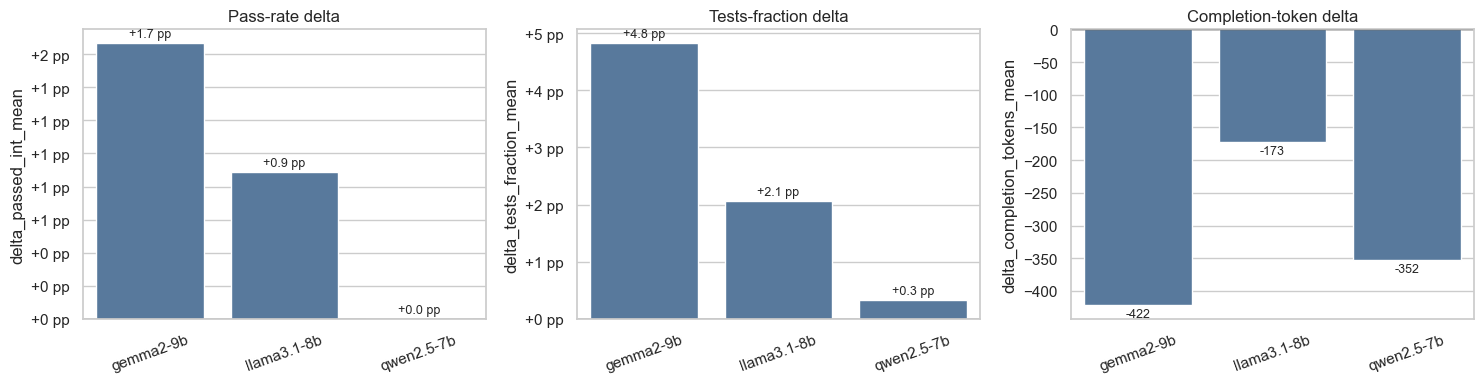

In [15]:
model_delta_long = model_deltas.melt(
    id_vars="model_short",
    value_vars=["delta_passed_int_mean", "delta_tests_fraction_mean", "delta_completion_tokens_mean", "delta_duration_seconds_mean", "delta_likely_code_only_mean"],
    var_name="metric",
    value_name="delta",
)
label_map = {
    "delta_passed_int_mean": "Pass-rate delta",
    "delta_tests_fraction_mean": "Tests-fraction delta",
    "delta_completion_tokens_mean": "Token delta",
    "delta_duration_seconds_mean": "Duration delta",
    "delta_likely_code_only_mean": "Code-only-rate delta",
}
model_delta_long["metric_label"] = model_delta_long["metric"].map(label_map)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title, percent in [
    (axes[0], "delta_passed_int_mean", "Pass-rate delta", True),
    (axes[1], "delta_tests_fraction_mean", "Tests-fraction delta", True),
    (axes[2], "delta_completion_tokens_mean", "Completion-token delta", False),
]:
    plot_data = model_deltas.copy()
    sns.barplot(data=plot_data, x="model_short", y=metric, ax=ax, color="#4C78A8")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    if percent:
        ax.yaxis.set_major_formatter(lambda x, pos: f"{100*x:+.0f} pp")
        for container in ax.containers:
            ax.bar_label(container, labels=[f"{100*v.get_height():+.1f} pp" for v in container], fontsize=9, padding=2)
    else:
        for container in ax.containers:
            ax.bar_label(container, labels=[f"{v.get_height():+.0f}" for v in container], fontsize=9, padding=2)
plt.tight_layout()
plt.show()

## Visual Summary: Tone Effects Under Each Condition

These charts answer: after forcing code-only output, does tone still matter?

The answer from the current data is yes: neutral remains strongest, but the gap is smaller than before.

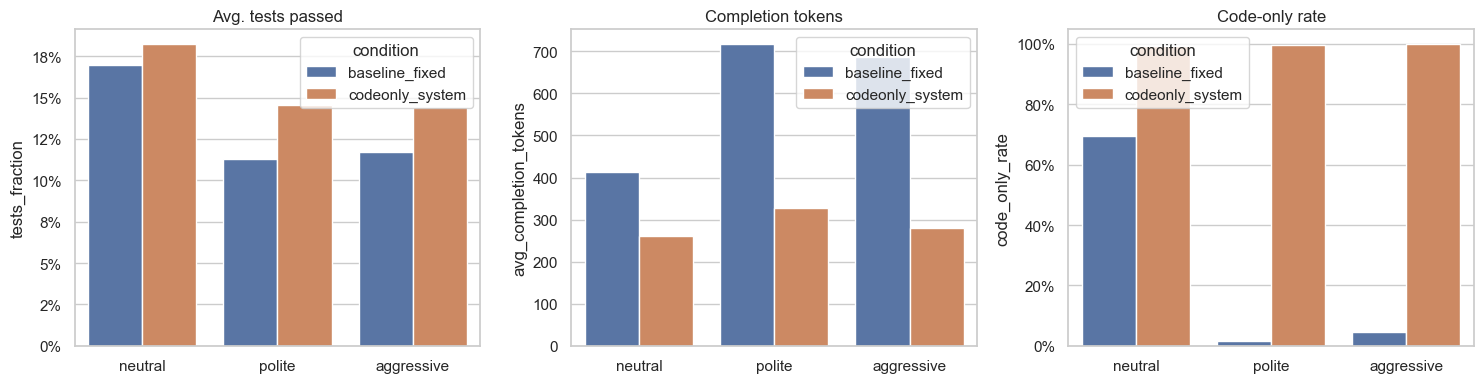

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in [
    (axes[0], "tests_fraction", "Avg. tests passed"),
    (axes[1], "avg_completion_tokens", "Completion tokens"),
    (axes[2], "code_only_rate", "Code-only rate"),
]:
    plot_data = condition_factor_summary[condition_factor_summary["factor"].eq("Tone")].copy()
    sns.barplot(data=plot_data, x="Tone", y=metric, hue="condition", ax=ax, order=["neutral", "polite", "aggressive"])
    ax.set_title(title)
    ax.set_xlabel("")
    if metric in ["tests_fraction", "code_only_rate"]:
        ax.yaxis.set_major_formatter(lambda x, pos: f"{100*x:.0f}%")
plt.tight_layout()
plt.show()

## Heatmap: Model × Tone Deltas

This heatmap shows where the code-only system prompt helped or hurt. Values are `codeonly_system - baseline_fixed`.

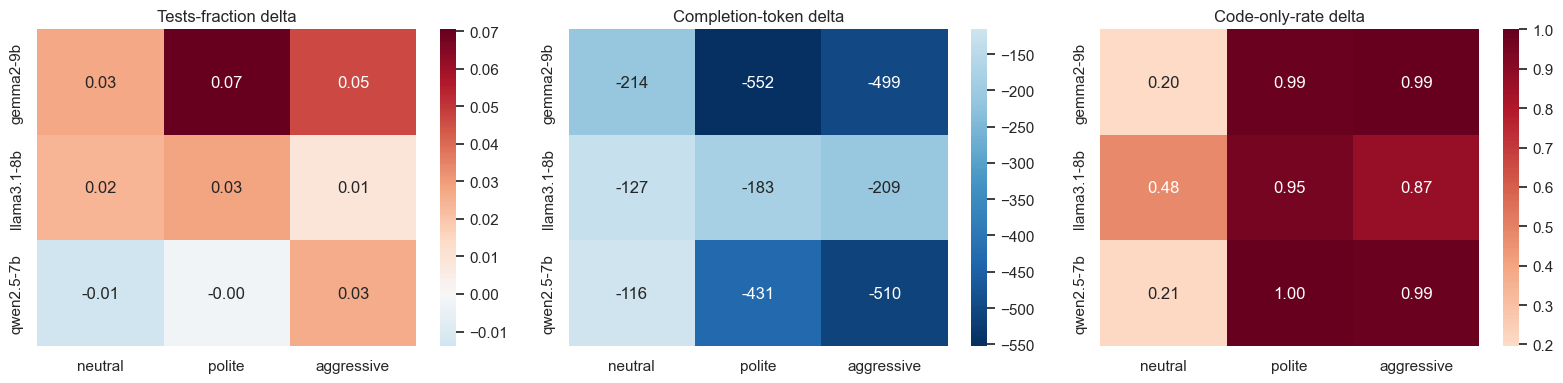

In [17]:
heat_metrics = [
    ("delta_tests_fraction_mean", "Tests-fraction delta"),
    ("delta_completion_tokens_mean", "Completion-token delta"),
    ("delta_likely_code_only_mean", "Code-only-rate delta"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (metric, title) in zip(axes, heat_metrics):
    pivot = model_tone_deltas.pivot(index="model_short", columns="Tone", values=metric)[["neutral", "polite", "aggressive"]]
    fmt = ".2f" if "tokens" not in metric else ".0f"
    sns.heatmap(pivot, annot=True, fmt=fmt, cmap="RdBu_r", center=0, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Factor Effect Coefficients Before vs Code-Only

This chart visualizes the fixed-effect regression coefficients for correctness. It shows which prompt factors remain meaningful under the code-only system prompt.

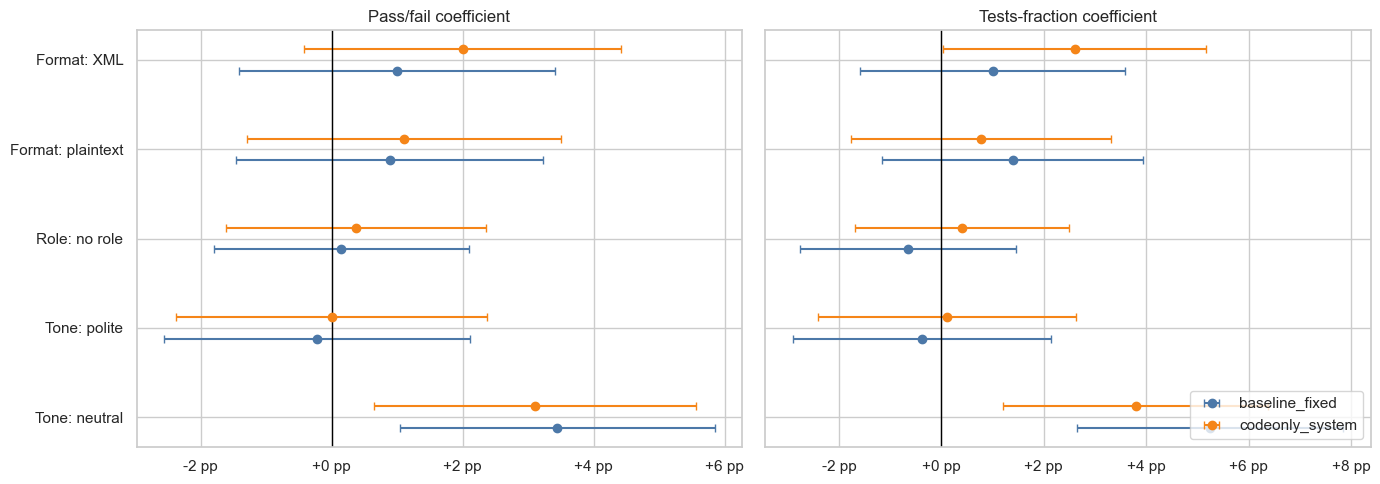

In [18]:
coef_plot = factor_regression[
    factor_regression["metric"].isin(["passed_int", "tests_fraction"])
    & factor_regression["term"].isin([
        "C(Tone)[T.neutral]", "C(Tone)[T.polite]",
        "C(Role_framing)[T.no role]",
        "C(Format)[T.plaintext]", "C(Format)[T.xml]",
    ])
].copy()
coef_plot["ci_low"] = coef_plot["coef"] - 1.96 * coef_plot["std_err"]
coef_plot["ci_high"] = coef_plot["coef"] + 1.96 * coef_plot["std_err"]
coef_plot["term_label"] = coef_plot["term"].replace({
    "C(Tone)[T.neutral]": "Tone: neutral",
    "C(Tone)[T.polite]": "Tone: polite",
    "C(Role_framing)[T.no role]": "Role: no role",
    "C(Format)[T.plaintext]": "Format: plaintext",
    "C(Format)[T.xml]": "Format: XML",
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric, title in [(axes[0], "passed_int", "Pass/fail coefficient"), (axes[1], "tests_fraction", "Tests-fraction coefficient")]:
    sub = coef_plot[coef_plot["metric"].eq(metric)].copy()
    y_order = ["Tone: neutral", "Tone: polite", "Role: no role", "Format: plaintext", "Format: XML"]
    offsets = {"baseline_fixed": -0.12, "codeonly_system": 0.12}
    for condition, color in [("baseline_fixed", "#4C78A8"), ("codeonly_system", "#F58518")]:
        csub = sub[sub["condition"].eq(condition)].copy()
        y = np.array([y_order.index(v) for v in csub["term_label"]]) + offsets[condition]
        ax.errorbar(
            csub["coef"], y,
            xerr=[csub["coef"] - csub["ci_low"], csub["ci_high"] - csub["coef"]],
            fmt="o", capsize=3, label=condition, color=color,
        )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(range(len(y_order)))
    ax.set_yticklabels(y_order)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(lambda x, pos: f"{100*x:+.0f} pp")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Write Short Markdown Summary

This writes a compact report to `analysis_outputs/codeonly_comparison/codeonly_comparison_report.md`.

In [19]:
def pct(x): return f"{100*x:.1f}%"
def pp(x): return f"{100*x:+.1f} pp"

over = summary.set_index("condition")
base = over.loc["baseline_fixed"]
co = over.loc["codeonly_system"]

def model_line(model):
    b = model_summary[(model_summary.model_short.eq(model)) & (model_summary.condition.eq("baseline_fixed"))].iloc[0]
    c = model_summary[(model_summary.model_short.eq(model)) & (model_summary.condition.eq("codeonly_system"))].iloc[0]
    return f"| {model} | {int(b.passes)}/900 ({pct(b.pass_rate)}) | {int(c.passes)}/900 ({pct(c.pass_rate)}) | {pp(c.pass_rate - b.pass_rate)} | {pp(c.tests_fraction - b.tests_fraction)} | {c.avg_completion_tokens - b.avg_completion_tokens:+.0f} | {pp(c.code_only_rate - b.code_only_rate)} |"

report = f"""# Code-Only System Prompt Comparison

System prompt tested:

> Output only the code, no explanations.

Baseline: corrected fixed-extractor results (`results/*_fixextractor.jsonl`).
Code-only condition: `results_codeonly/*.jsonl`.

## Overall Result

| Condition | Passes | Pass rate | Avg. tests passed | Avg. completion tokens | Avg. duration | Code-only rate |
|---|---:|---:|---:|---:|---:|---:|
| baseline_fixed | {int(base.passes)}/2700 | {pct(base.pass_rate)} | {pct(base.tests_fraction)} | {base.avg_completion_tokens:.0f} | {base.avg_duration_seconds:.2f}s | {pct(base.code_only_rate)} |
| codeonly_system | {int(co.passes)}/2700 | {pct(co.pass_rate)} | {pct(co.tests_fraction)} | {co.avg_completion_tokens:.0f} | {co.avg_duration_seconds:.2f}s | {pct(co.code_only_rate)} |

Overall, the code-only system prompt changed exact passes from {int(base.passes)}/2700 to {int(co.passes)}/2700, a pass-rate change of {pp(co.pass_rate - base.pass_rate)}. It changed average tests passed by {pp(co.tests_fraction - base.tests_fraction)}, completion length by {co.avg_completion_tokens - base.avg_completion_tokens:+.0f} tokens, and code-only rate by {pp(co.code_only_rate - base.code_only_rate)}.

## By Model

| Model | Baseline passes | Code-only passes | Pass-rate delta | Tests-fraction delta | Token delta | Code-only-rate delta |
|---|---:|---:|---:|---:|---:|---:|
"""
for model in sorted(model_summary.model_short.unique()):
    report += model_line(model) + "\n"

report += """

## Interpretation

The system prompt improves measured exact pass rate overall, but the effect is model-specific. It helps Gemma and Llama, while Qwen's exact pass count is unchanged. The comparison should be interpreted as a controlled prompt-policy intervention: adding a global code-only instruction changes output behavior and modestly changes downstream performance.

The key research implication is that explicit output constraints can reduce evaluator-compliance problems, but they do not remove prompt-factor effects entirely. Under the code-only system prompt, tone still affects performance: neutral remains best overall by tests fraction, while polite/aggressive improve more than neutral because they had the largest verbosity/compliance problem in the baseline. Role framing remains small, and format effects remain modest/model-dependent.
"""

report_path = OUTPUT_DIR / "codeonly_comparison_report.md"
report_path.write_text(report, encoding="utf-8")
print(report_path)
print(report)

/Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/codeonly_comparison/codeonly_comparison_report.md
# Code-Only System Prompt Comparison

System prompt tested:

> Output only the code, no explanations.

Baseline: corrected fixed-extractor results (`results/*_fixextractor.jsonl`).
Code-only condition: `results_codeonly/*.jsonl`.

## Overall Result

| Condition | Passes | Pass rate | Avg. tests passed | Avg. completion tokens | Avg. duration | Code-only rate |
|---|---:|---:|---:|---:|---:|---:|
| baseline_fixed | 254/2700 | 9.4% | 13.3% | 605 | 18.16s | 25.2% |
| codeonly_system | 277/2700 | 10.3% | 15.7% | 290 | 9.00s | 99.5% |

Overall, the code-only system prompt changed exact passes from 254/2700 to 277/2700, a pass-rate change of +0.9 pp. It changed average tests passed by +2.4 pp, completion length by -316 tokens, and code-only rate by +74.3 pp.

## By Model

| Model | Baseline passes | Code-only passes | Pass-rate delta | Tests-frac